# Composite-Composite Failure Mode

## Imports

In [1]:
import os
import json
import time
import pickle
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor, CatBoostClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GroupKFold, KFold, GridSearchCV, train_test_split, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, BayesianRidge, LogisticRegression
from sklearn.svm import SVR, SVC
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier, ExtraTreesRegressor, ExtraTreesClassifier,
                              GradientBoostingRegressor, GradientBoostingClassifier, AdaBoostRegressor, AdaBoostClassifier)
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.gaussian_process import GaussianProcessRegressor, GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF, Matern, WhiteKernel, ConstantKernel as C

warnings.filterwarnings('ignore')
sns.set_theme(style='ticks', context='notebook')

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

In [2]:
TASK = 'Composite_Composite__FailureMode'
FOLDER = 'Composite_Composite'
SEED = 42
SCORING = 'f1_macro'
RESULTS = '../results'
os.makedirs(f'{RESULTS}/models', exist_ok=True)

## Data

In [3]:
df = pd.read_csv(f'../data/processed/{FOLDER}/{TASK}.csv')
df.head()

,Row_ID,Paper_ID,Value_Type,Target_Is_Derived,No_Plies,Adherend1_Thickness_mm,Adherend2_Thickness_mm,Adherend1_Modulus_GPa,Adherend2_Modulus_GPa,Adherend1_Strength_MPa,...,Surf_Peel_ply,Surf_Plasma_corona,Surf_UV_ozone,Surf_Laser,Surf_Chemical_electrochemical,Surf_Other_modifier,Surf_None_as_received,Surf_Ultrasonic_vibration_assisted,Surf_Unknown,Failure_Mode
0,3,1,Single,0,8.0,NaN,NaN,0.305,0.305,63.85,...,0,0,0,0,0,0,0,0,0,3
1,4,1,Single,0,8.0,NaN,NaN,0.305,0.305,63.85,...,0,0,0,0,0,0,0,0,0,3
2,5,1,Single,0,8.0,NaN,NaN,0.305,0.305,63.85,...,0,0,0,0,0,0,0,0,0,3
3,6,1,Single,0,8.0,NaN,NaN,0.305,0.305,63.85,...,0,0,0,0,0,0,0,0,0,3
4,7,1,Single,0,8.0,NaN,NaN,0.305,0.305,63.85,...,0,0,0,0,0,0,0,0,0,3


In [4]:
print(df.shape, df['Paper_ID'].nunique())
df.describe().T

(812, 52) 42


,count,mean,std,min,25%,50%,75%,max
Row_ID,812.0,782.161330,446.160256,3.0000,330.75,904.500,1179.2500,1416.000000
Paper_ID,812.0,44.584975,21.769194,1.0000,24.00,50.000,64.0000,72.000000
Target_Is_Derived,812.0,0.000000,0.000000,0.0000,0.00,0.000,0.0000,0.000000
No_Plies,529.0,9.198488,4.727851,2.0000,7.00,8.000,12.0000,32.000000
Adherend1_Thickness_mm,740.0,2.173703,0.688484,0.8000,1.52,2.000,2.5400,5.000000
Adherend2_Thickness_mm,740.0,2.173703,0.688484,0.8000,1.52,2.000,2.5400,5.000000
Adherend1_Modulus_GPa,487.0,76.998480,50.017927,0.3050,61.60,72.000,75.0000,230.000000
Adherend2_Modulus_GPa,487.0,76.998480,50.017927,0.3050,61.60,72.000,75.0000,230.000000
Adherend1_Strength_MPa,286.0,848.612308,686.848507,34.2700,250.00,650.000,1800.0000,2180.000000
Adherend2_Strength_MPa,286.0,848.612308,686.848507,34.2700,250.00,650.000,1800.0000,2180.000000


In [5]:
classes = {0: 'Adhesive', 1: 'Cohesive', 2: 'Mixed', 3: 'Substrate'}
df['Failure_Mode'].map(classes).value_counts()

Failure_Mode
Cohesive     275
Mixed        248
Substrate    211
Adhesive      78
Name: count, dtype: int64

## Train-Test Split

In [6]:
meta_cols = ['Row_ID', 'Paper_ID', 'Value_Type', 'Target_Is_Derived']
target = df.columns[-1]

X = df.drop(columns=meta_cols + [target])
y = df[target]
groups = df['Paper_ID'].values

idx = np.arange(len(df))
train_idx, test_idx = train_test_split(idx, test_size=0.2, random_state=SEED)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print(len(train_idx), len(test_idx), len(set(groups[train_idx])), 'studies in the training part')

649 163 42 studies in the training part


## Helper Functions

In [7]:
FAMILY = {'OLS': 'Linear', 'Ridge': 'Linear', 'Lasso': 'Linear', 'ElasticNet': 'Linear', 'LogReg-L2': 'Linear', 'LogReg-L1': 'Linear',
          'SVR': 'Kernel', 'SVC': 'Kernel', 'MLP': 'Neural net', 'DT': 'Tree', 'RF': 'Forest', 'ET': 'Forest',
          'GB': 'Boosting', 'XGB': 'Boosting', 'LGBM': 'Boosting', 'AB': 'Boosting', 'CatBoost': 'Boosting',
          'KNN': 'Nearest neighbour', 'BayesRidge': 'Bayesian', 'GPR': 'Bayesian', 'GPC': 'Bayesian', 'GNB': 'Bayesian'}


def make_pipeline(model, impute=True, scale_target=False):
    # median imputation (fitted on the training data), MinMax scaling to [0, 1], then the model
    if scale_target and not True:
        model = TransformedTargetRegressor(regressor=model, transformer=StandardScaler())
    steps = [('imputer', SimpleImputer(strategy='median'))] if impute else []
    return Pipeline(steps + [('scaler', MinMaxScaler()), ('model', model)])


def get_scores(y_true, y_pred):
    if True:
        return dict(acc=accuracy_score(y_true, y_pred), f1=f1_score(y_true, y_pred, average='macro'))
    return dict(r2=r2_score(y_true, y_pred), mae=mean_absolute_error(y_true, y_pred), mse=mean_squared_error(y_true, y_pred))

In [8]:
results = []
predictions = {}
fitted = {}
KEY = 'f1'


def evaluate(name, model, param_grid, impute=True, scale_target=False):
    start = time.time()
    prefix = 'model__regressor__' if (scale_target and not True) else 'model__'
    n_splits = min(5, len(set(groups[train_idx])))

    # Step 1: grid search on the training part, folds grouped by study
    grid = GridSearchCV(make_pipeline(model, impute, scale_target), {prefix + k: v for k, v in param_grid.items()},
                        cv=GroupKFold(n_splits), scoring=SCORING, n_jobs=2, refit=False, error_score=np.nan)
    grid.fit(X_train, y_train, groups=groups[train_idx])
    best_params = {k[len(prefix):]: v for k, v in grid.best_params_.items()}
    build = lambda: make_pipeline(clone(model).set_params(**best_params), impute, scale_target)

    # Step 2: refit on the whole training part and score both parts
    t0 = time.perf_counter()
    best = build().fit(X_train, y_train)
    fit_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred_test = best.predict(X_test)
    pred_time = (time.perf_counter() - t0) / len(test_idx) * 1000
    pred_train = best.predict(X_train)
    train_scores = get_scores(y_train, pred_train)
    test_scores = get_scores(y_test, pred_test)

    # Step 3: random 5-fold on the training part (leakage diagnostic) and study-grouped out-of-fold predictions
    random_cv = cross_val_predict(build(), X_train, y_train, cv=KFold(5, shuffle=True, random_state=0))
    oof = cross_val_predict(build(), X_train, y_train, cv=GroupKFold(n_splits), groups=groups[train_idx])

    # Step 4: five further random 80:20 splits with the tuned settings
    seeds = []
    for s in range(5):
        a, b = train_test_split(idx, test_size=0.2, random_state=s)
        p = build().fit(X.iloc[a], y.iloc[a]).predict(X.iloc[b])
        seeds.append(get_scores(y.iloc[b], p)[KEY])

    proba = None
    if True and hasattr(best, 'predict_proba'):
        try:
            proba = best.predict_proba(X_test)
        except Exception:
            proba = None

    fitted[name] = best
    predictions[name] = dict(train_idx=train_idx, test_idx=test_idx, y_train=y_train.values, y_test=y_test.values,
                             pred_train=pred_train, pred_test=pred_test, oof=oof, random_cv=random_cv, proba=proba)
    joblib.dump(best, f'{RESULTS}/models/{TASK}__{name}.joblib')
    row = dict(File=TASK, Target=target, Family=FAMILY[name], Model=name, Rows=len(df), Papers=len(set(groups)),
               Best_params=json.dumps({k: str(v) for k, v in best_params.items()}),
               GroupCV_tuned=round(grid.best_score_, 4),
               GroupOOF_score=round(get_scores(y_train, oof)[KEY], 4),
               Random5fold_score=round(get_scores(y_train, random_cv)[KEY], 4))
    row.update({f'Train_{k}': round(v, 4) for k, v in train_scores.items()})
    row.update({f'Test_{k}': round(v, 4) for k, v in test_scores.items()})
    row.update(Test5seeds_mean=round(float(np.mean(seeds)), 4), Test5seeds_sd=round(float(np.std(seeds)), 4),
               Fit_s=round(fit_time, 3), Pred_ms_per_row=round(pred_time, 4))
    results.append(row)
    print(name, f'test {KEY} = {test_scores[KEY]:.3f}', f'group CV = {grid.best_score_:.3f}', f'{time.time() - start:.0f}s')

## Logistic Regression (L2)

In [9]:
model = LogisticRegression(max_iter=5000)
param_grid = {'C': [0.1, 1, 10, 100]}
evaluate('LogReg-L2', model, param_grid)

LogReg-L2 test f1 = 0.736 group CV = 0.217 3s


## Logistic Regression (L1)

In [10]:
model = LogisticRegression(penalty='l1', solver='saga', max_iter=5000)
param_grid = {'C': [0.1, 1, 10, 100]}
evaluate('LogReg-L1', model, param_grid)

LogReg-L1 test f1 = 0.806 group CV = 0.272 45s


## SVC

In [11]:
model = SVC(probability=True, random_state=0)
param_grid = {'C': [1, 10, 100], 'gamma': [0.01, 0.05, 0.2]}
evaluate('SVC', model, param_grid)

SVC test f1 = 0.830 group CV = 0.188 3s


## MLP

In [12]:
model = MLPClassifier(max_iter=2000, early_stopping=True, random_state=0)
param_grid = {'hidden_layer_sizes': [(64,), (128, 64)], 'alpha': [1e-4, 1e-2]}
evaluate('MLP', model, param_grid)

MLP test f1 = 0.568 group CV = 0.169 4s


## Decision Tree

In [13]:
model = DecisionTreeClassifier(random_state=0)
param_grid = {'max_depth': [6, 12, None], 'min_samples_leaf': [1, 3]}
evaluate('DT', model, param_grid)

DT test f1 = 0.818 group CV = 0.252 1s


## RF

In [14]:
model = RandomForestClassifier(random_state=0, n_jobs=1)
param_grid = {'n_estimators': [200, 400], 'max_depth': [None, 12], 'min_samples_leaf': [1, 2]}
evaluate('RF', model, param_grid)

RF test f1 = 0.792 group CV = 0.226 18s


## Extra Trees

In [15]:
model = ExtraTreesClassifier(random_state=0, n_jobs=1)
param_grid = {'n_estimators': [200, 400], 'max_depth': [None, 12], 'min_samples_leaf': [1, 2]}
evaluate('ET', model, param_grid)

ET test f1 = 0.855 group CV = 0.244 13s


## GB

In [16]:
model = GradientBoostingClassifier(random_state=0)
param_grid = {'n_estimators': [100, 200], 'max_depth': [3, 5]}
evaluate('GB', model, param_grid)

GB test f1 = 0.906 group CV = 0.207 23s


## XGB

In [17]:
model = xgb.XGBClassifier(random_state=0, n_jobs=1, subsample=0.8, colsample_bytree=0.8)
param_grid = {'n_estimators': [300, 600], 'max_depth': [4, 6], 'learning_rate': [0.05, 0.1]}
evaluate('XGB', model, param_grid, impute=False)

XGB test f1 = 0.905 group CV = 0.170 17s


## LGBM

In [18]:
model = lgb.LGBMClassifier(random_state=0, n_jobs=1, verbose=-1)
param_grid = {'n_estimators': [300, 600], 'num_leaves': [15, 31], 'learning_rate': [0.05, 0.1]}
evaluate('LGBM', model, param_grid, impute=False)

LGBM test f1 = 0.905 group CV = 0.280 15s


## Adaboost

In [19]:
model = AdaBoostClassifier(random_state=0)
param_grid = {'n_estimators': [100, 300], 'learning_rate': [0.1, 0.5, 1.0]}
evaluate('AB', model, param_grid)

AB test f1 = 0.673 group CV = 0.195 10s


## CatBoost

In [20]:
model = CatBoostClassifier(random_seed=0, verbose=0, thread_count=1, allow_writing_files=False)
param_grid = {'iterations': [300, 600], 'depth': [4, 6], 'learning_rate': [0.05, 0.1]}
evaluate('CatBoost', model, param_grid, impute=False)

CatBoost test f1 = 0.837 group CV = 0.169 21s


## KNN

In [21]:
model = KNeighborsClassifier()
param_grid = {'n_neighbors': [3, 4, 5, 6, 7], 'weights': ['uniform', 'distance']}
evaluate('KNN', model, param_grid)

KNN test f1 = 0.896 group CV = 0.167 2s


## Gaussian Naive Bayes

In [22]:
model = GaussianNB()
param_grid = {'var_smoothing': [1e-9, 1e-6, 1e-3, 1e-1]}
evaluate('GNB', model, param_grid)

GNB test f1 = 0.688 group CV = 0.320 0s


## Gaussian Process

In [23]:
kernels = [C(1.0) * Matern(1.0, nu=1.5), C(1.0) * RBF(1.0)]
model = GaussianProcessClassifier(random_state=0)
param_grid = {'kernel': kernels}
evaluate('GPC', model, param_grid)

GPC test f1 = 0.911 group CV = 0.141 149s


## Results

In [24]:
results_df = pd.DataFrame(results)
results_df.to_csv(f'{RESULTS}/{TASK}__zoo_results.csv', index=False)
cols = ['Model', 'Family', 'Train_f1', 'Test_f1', 'Test5seeds_mean', 'Test5seeds_sd', 'GroupOOF_score']
results_df[cols].sort_values('Test_f1', ascending=False).reset_index(drop=True)

,Model,Family,Train_f1,Test_f1,Test5seeds_mean,Test5seeds_sd,GroupOOF_score
0,GPC,Bayesian,0.9723,0.9111,0.9291,0.0159,0.1545
1,GB,Boosting,0.9763,0.9064,0.9250,0.0134,0.2502
2,LGBM,Boosting,0.9736,0.9051,0.9191,0.0258,0.3357
3,XGB,Boosting,0.9762,0.9051,0.9239,0.0265,0.1719
4,KNN,Nearest neighbour,0.9762,0.8955,0.9299,0.0168,0.1666
5,ET,Forest,0.9484,0.8547,0.9162,0.0115,0.2527
6,CatBoost,Boosting,0.9412,0.8375,0.9149,0.0196,0.1931
7,SVC,Kernel,0.9331,0.8303,0.8813,0.0244,0.1877
8,DT,Tree,0.9237,0.8180,0.8520,0.0209,0.2857
9,LogReg-L1,Linear,0.8891,0.8062,0.8691,0.0232,0.2427


## Model Families

In [25]:
results_df.groupby('Family')['Test_f1'].agg(['mean', 'max', 'count']).sort_values('mean', ascending=False)

,mean,max,count
Family,,,
Nearest neighbour,0.89550,0.8955,1
Boosting,0.84548,0.9064,5
Kernel,0.83030,0.8303,1
Forest,0.82355,0.8547,2
Tree,0.81800,0.8180,1
Bayesian,0.79950,0.9111,2
Linear,0.77135,0.8062,2
Neural net,0.56850,0.5685,1


## Confusion Matrix

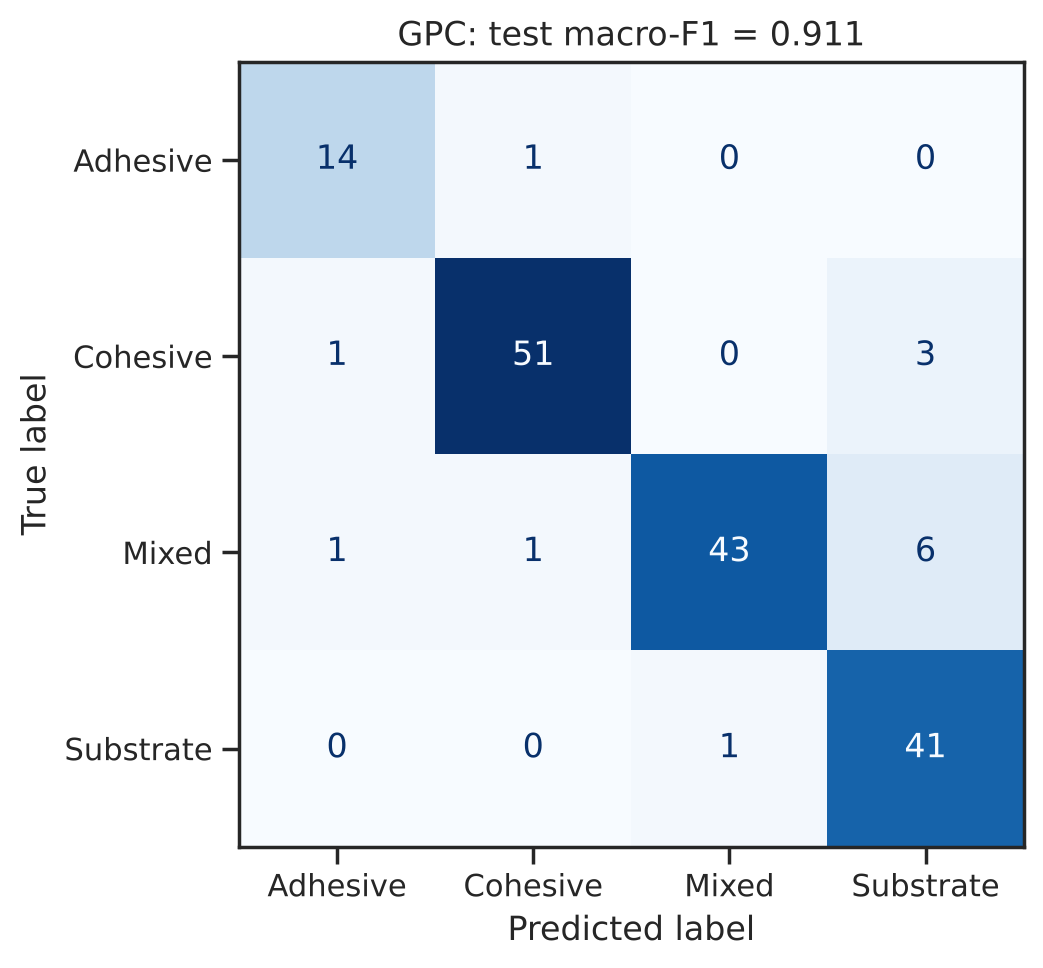

F1 per class: [0.903 0.944 0.905 0.891]


In [26]:
best_name = results_df.loc[results_df['Test_f1'].idxmax(), 'Model']
p = predictions[best_name]
labels = [0, 1, 2, 3]
cm = confusion_matrix(p['y_test'], p['pred_test'], labels=labels)
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=['Adhesive', 'Cohesive', 'Mixed', 'Substrate']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'{best_name}: test macro-F1 = {results_df.set_index("Model").loc[best_name, "Test_f1"]:.3f}')
plt.tight_layout()
plt.show()
print('F1 per class:', np.round(f1_score(p['y_test'], p['pred_test'], average=None, labels=labels), 3))

## Permutation Importance

In [27]:
importance = {}
for name, fitted_model in fitted.items():
    r = permutation_importance(fitted_model, X_test, y_test, scoring=SCORING, n_repeats=3, random_state=0, n_jobs=2)
    importance[name] = r.importances_mean
importance = pd.DataFrame(importance, index=X.columns)
importance.to_csv(f'{RESULTS}/{TASK}__permutation_importance.csv')
importance.mean(axis=1).sort_values(ascending=False).head(12)

Adhesive_Thickness_mm                      0.054388
Primer_Used                                0.044092
Fiber_Orientation_Class                    0.040050
Surf_Solvent_detergent_clean               0.039052
Surf_Plasma_corona                         0.034458
Cure_Temp_C                                0.030649
Surf_Unknown                               0.027758
Surf_Abrasion_sanding_grinding_brushing    0.026758
Adherend1_Class                            0.023498
Humidity_pctRH                             0.023112
Joint_Width_mm                             0.019550
Overlap_Length_mm                          0.018644
dtype: float64

## SHAP Analysis

In [28]:
# best tree-based model of the task
tree_models = ['RF', 'ET', 'XGB', 'LGBM', 'CatBoost', 'DT'] + ([] if True else ['GB'])
test_scores = results_df.set_index('Model')['Test_f1']
best_tree = test_scores[test_scores.index.isin(tree_models)].idxmax()
print('SHAP model:', best_tree)

pipe_tree = fitted[best_tree]
X_scaled = pd.DataFrame(pipe_tree[:-1].transform(X), columns=X.columns)
explainer = shap.TreeExplainer(pipe_tree[-1])
shap_values = explainer.shap_values(X_scaled, check_additivity=False)
if isinstance(shap_values, list):
    shap_values = np.stack(shap_values, axis=-1)
shap_values = np.asarray(shap_values)

# mean absolute SHAP value (averaged over classes for the classifiers)
abs_shap = np.abs(shap_values).mean(axis=tuple(i for i in range(shap_values.ndim) if i != 1))
importance_df = pd.DataFrame({'Feature': X.columns, 'Mean_Abs_SHAP': abs_shap}).sort_values('Mean_Abs_SHAP', ascending=False)
importance_df.to_csv(f'{RESULTS}/{TASK}__shap_importance.csv', index=False)
importance_df.head(12)

SHAP model: XGB


,Feature,Mean_Abs_SHAP
15,Adhesive_Thickness_mm,0.519436
3,Adherend1_Modulus_GPa,0.425121
9,Mix_Ratio_A_per_B,0.325755
13,Overlap_Length_mm,0.315743
35,Surf_Solvent_detergent_clean,0.302223
11,Adhesive_Strength_MPa,0.275151
26,Fiber_Orientation_Class,0.254470
22,Humidity_pctRH,0.251770
41,Surf_Laser,0.246201
17,Cure_Duration_h,0.218769


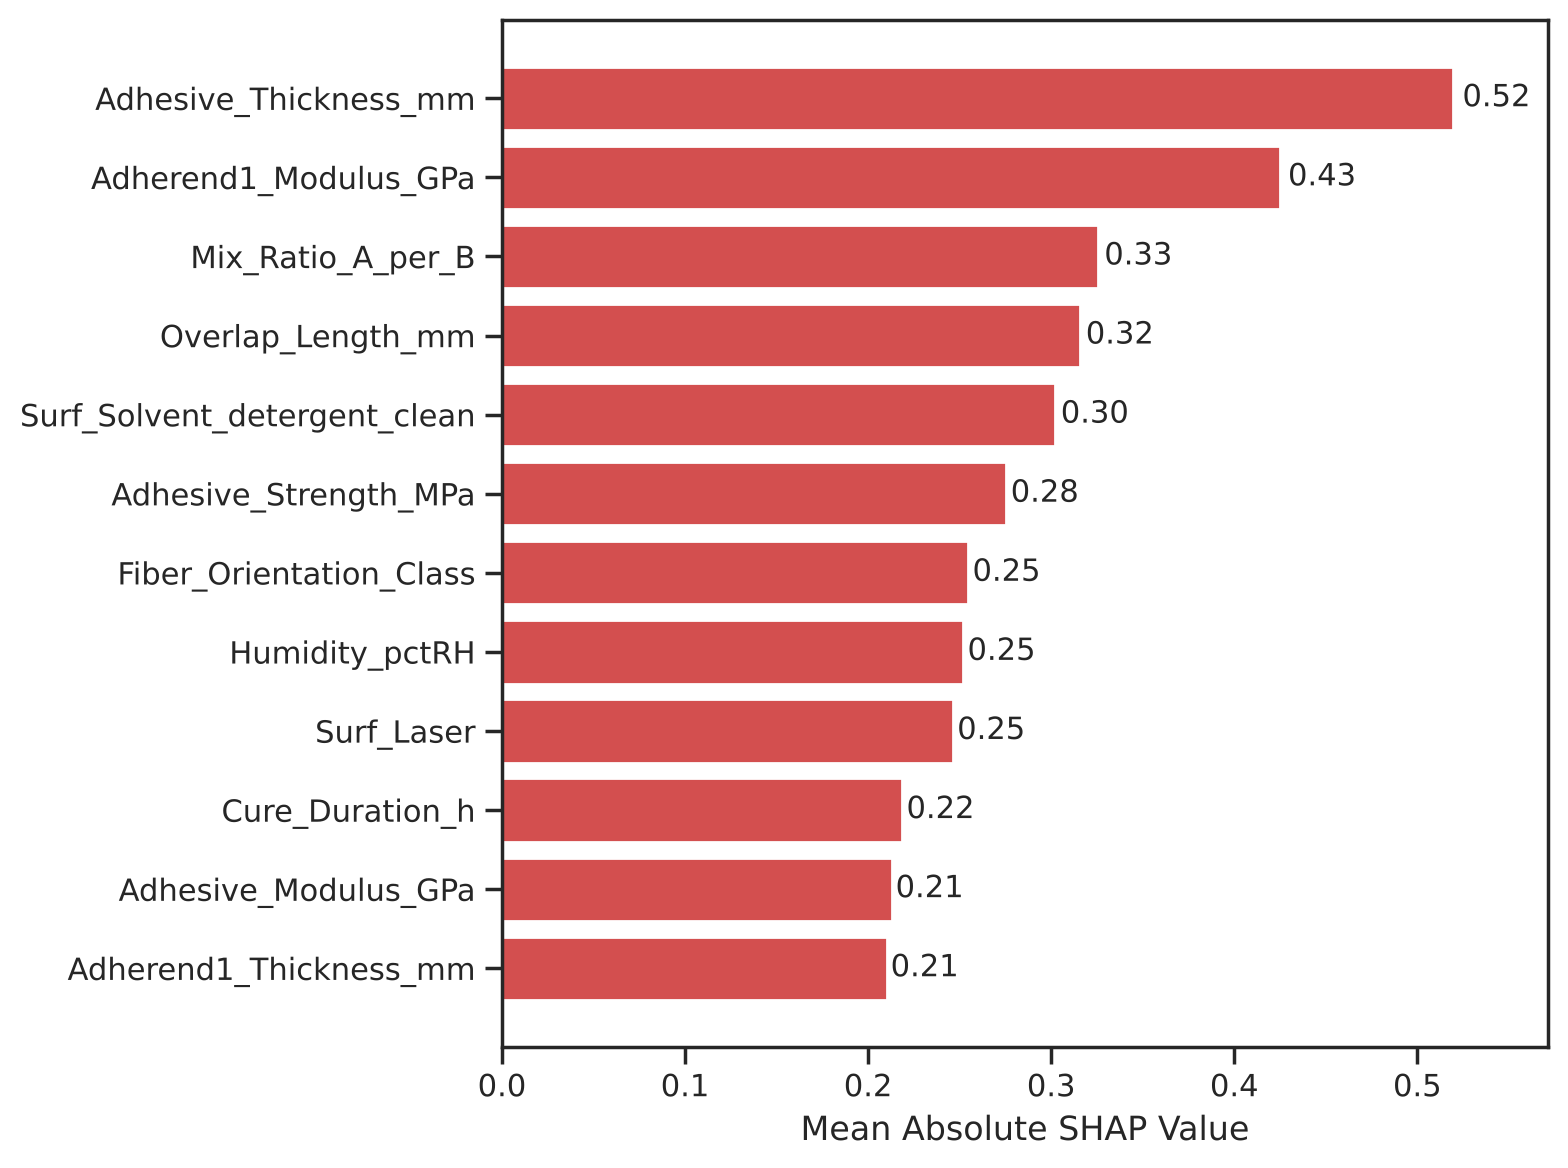

In [29]:
# Horizontal bar plot for feature importance with value labels
plt.figure(figsize=(8, 6))
top_features = importance_df.head(12).iloc[::-1]
bars = plt.barh(top_features['Feature'], top_features['Mean_Abs_SHAP'], color='#d34f4f')
for bar in bars:
    width = bar.get_width()
    plt.text(width * 1.01, bar.get_y() + bar.get_height() / 2, f'{width:.2f}', ha='left', va='center', fontsize=11)
plt.xlabel('Mean Absolute SHAP Value')
plt.margins(x=0.1)
plt.tight_layout()
plt.show()

## Save

In [30]:
with open(f'{RESULTS}/{TASK}__predictions.pkl', 'wb') as fh:
    pickle.dump(predictions, fh)
np.save(f'{RESULTS}/{TASK}__shap_values.npy', shap_values)